# Módulo 1 — O que é avaliação baseada em mercado

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulos 1 e 2 do livro.

## O que você vai conseguir fazer ao final

1. Escrever o payoff de calls e puts, e dizer quem paga o quê a quem.
2. Explicar por que o valor de uma opção **não** é a média simples do que ela pode pagar.
3. Calcular o valor de uma opção europeia por simulação e pela fórmula de Black-Scholes-Merton (BSM), e conferir uma contra a outra.
4. Separar valor intrínseco de valor no tempo e saber quando este último pode ser negativo.
5. Listar os riscos que movem o preço de uma opção e medir o efeito de cada um.
6. Mostrar, com números, por que o hedge dinâmico funciona num mundo sem saltos e falha num mundo com saltos.
7. Executar, em miniatura, as seis etapas do processo que o resto do curso aprofunda.

## Como estudar este notebook

Leia cada bloco de teoria **antes** de rodar a célula seguinte, e tente prever o resultado. Cada laboratório termina com verificações (`ok(...)`): se o notebook roda até o fim, todas as contas foram conferidas.

Neste módulo algumas ferramentas aparecem como **caixa-preta** (a fórmula BSM, a dinâmica lognormal). Isso é proposital: primeiro vemos o que elas fazem, depois as deduzimos do zero nos módulos 3 a 5.

## Mapa do curso

| Módulo | Tema | Livro |
|---|---|---|
| **1** | **Avaliação baseada em mercado** | **Caps. 1-2** |
| 2 | Fatos estilizados e volatilidade implícita | Cap. 3 |
| 3 | Neutralidade ao risco em tempo discreto | Cap. 4 |
| 4 | Tempo contínuo: Browniano, Itô, Girsanov | Cap. 4 |
| 5 | BSM: a EDP, a fórmula e as gregas | Cap. 5 |
| 6 | Árvore binomial CRR e convergência | Cap. 5 |
| 7 | Fourier I: transformada e método de Lewis | Cap. 6 |
| 8 | Fourier II: Carr-Madan, FFT e convolução | Cap. 6 |
| 9 | Opções americanas: Least-Squares Monte Carlo e dual | Cap. 7 |
| 10 | Primeiro exemplo completo: Merton (1976) | Cap. 8 |
| 11 | Modelo geral BCC97: Heston + saltos + CIR | Cap. 9 |
| 12 | Monte Carlo: discretização e redução de variância | Cap. 10 |
| 13 | Calibração I: curva de juros (CIR) e Heston | Cap. 11 |
| 14 | Calibração II: saltos e BCC97 completo | Cap. 11 |
| 15 | Simulação e avaliação no modelo geral | Cap. 12 |
| 16 | Hedge dinâmico e síntese | Caps. 13-14 |
| 17 | Complemento: Hull-White I — medidas, modelo e fórmulas fechadas | — |
| 18 | Complemento: Hull-White II — árvore trinomial | — |
| 19 | Complemento: simulação de trajetórias de juros, do Vasicek ao HJM | — |
| 20 | Complemento: árvores implícitas de Derman-Kani-Chriss (interativo) | — |

As ferramentas do Apêndice A do livro (regressão, splines, otimização, integração) entram no módulo em que são usadas pela primeira vez.

## 0. Preparação

A célula abaixo importa as bibliotecas e define três utilitários: `f3` (número com três casas decimais e vírgula), `tabela` (mostra um DataFrame nesse formato) e `ok` (verificação com contagem).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, poisson
from scipy.optimize import brentq, least_squares
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    display(df.map(lambda v: f3(v) if isinstance(v, (float, np.floating)) else v))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


print("Ambiente pronto. Exemplo de formato:", f3(1234.5678))

Ambiente pronto. Exemplo de formato: 1.234,568


---
## 1. O contrato: o que é uma opção

**Livro: §2.1**

Uma **opção** é um contrato que dá a quem compra um **direito**, sem obrigação:

- a **call** dá o direito de **comprar** o ativo-objeto por um preço combinado;
- a **put** dá o direito de **vender** o ativo-objeto por um preço combinado.

Quatro palavras aparecem o tempo todo:

| Termo | Significado |
|---|---|
| **Strike** ($K$) | o preço combinado |
| **Vencimento** ($T$) | a data em que o direito acaba |
| **Titular** (*holder*) | quem comprou o direito e pagou o prêmio |
| **Lançador** (*writer*) | quem vendeu o direito e assumiu a obrigação |

Quanto ao momento de exercício: a **europeia** só pode ser exercida no vencimento; a **americana**, a qualquer momento até o vencimento.

Opções sobre índice são **liquidadas financeiramente**: ninguém entrega "um índice". O lançador apenas paga a diferença em dinheiro.

### Passo a passo do payoff

Considere uma call europeia sobre um índice, com $K = 8.000$.

**Cenário 1: o índice fecha em 8.200.** O titular tem o direito de "comprar" a 8.000 algo que vale 8.200. Ele exerce e recebe a diferença: $8.200 - 8.000 = 200$.

**Cenário 2: o índice fecha em 7.800.** Comprar a 8.000 algo que vale 7.800 seria perder 200. Como é um direito e não uma obrigação, ele não exerce e recebe zero.

Os dois cenários cabem numa única expressão, o **payoff** (ou valor intrínseco no vencimento):

$$h_T^{\text{call}} = \max(S_T - K,\ 0)$$

Para a put, o raciocínio é espelhado:

$$h_T^{\text{put}} = \max(K - S_T,\ 0)$$

Repare em duas propriedades que vão importar muito:

1. O payoff **nunca é negativo** para o titular. É por isso que ele paga um prêmio para entrar no contrato.
2. O payoff tem uma **quina** em $S_T = K$. Ele é uma função **convexa**, e veremos que essa convexidade é a origem do valor da volatilidade.

In [2]:
def payoff_call(S, K):
    return np.maximum(S - K, 0.0)


def payoff_put(S, K):
    return np.maximum(K - S, 0.0)


K = 8000.0
ok(payoff_call(8200.0, K) == 200.0, "call com índice em 8.200 paga 200")
ok(payoff_call(7800.0, K) == 0.0, "call com índice em 7.800 paga zero")
ok(payoff_put(7800.0, K) == 200.0, "put com índice em 7.800 paga 200")

OK — call com índice em 8.200 paga 200
OK — call com índice em 7.800 paga zero
OK — put com índice em 7.800 paga 200


### Laboratório 1.1 — As quatro posições básicas

Uma opção é um **jogo de soma zero** entre as duas pontas: o que o titular recebe, o lançador paga. Comprar e vender calls e puts gera quatro perfis. Antes de rodar, tente desenhar os quatro de cabeça.

Os gráficos mostram só o payoff no vencimento, sem considerar o prêmio pago ou recebido.

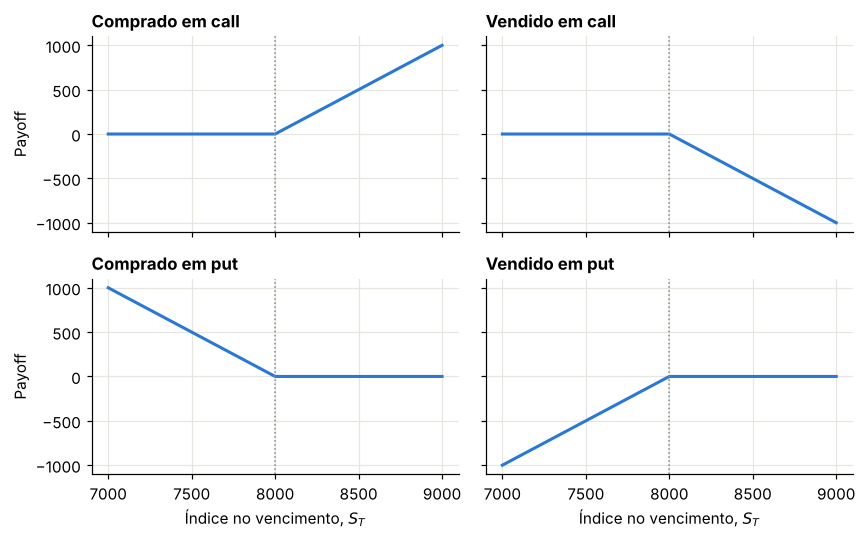

OK — soma zero entre titular e lançador da call
OK — soma zero entre titular e lançador da put


In [3]:
S = np.linspace(7000, 9000, 401)
perfis = {
    "Comprado em call": payoff_call(S, K),
    "Vendido em call": -payoff_call(S, K),
    "Comprado em put": payoff_put(S, K),
    "Vendido em put": -payoff_put(S, K),
}

fig, eixos = plt.subplots(2, 2, figsize=(8, 5), sharex=True, sharey=True)
for ax, (nome, h) in zip(eixos.ravel(), perfis.items()):
    ax.plot(S, h, color=AZUL)
    ax.axvline(K, color=CINZA, lw=1, ls=":")
    ax.set_title(nome)
for ax in eixos[1]:
    ax.set_xlabel("Índice no vencimento, $S_T$")
for ax in eixos[:, 0]:
    ax.set_ylabel("Payoff")
plt.tight_layout()
plt.show()

ok(np.allclose(perfis["Comprado em call"] + perfis["Vendido em call"], 0), "soma zero entre titular e lançador da call")
ok(np.allclose(perfis["Comprado em put"] + perfis["Vendido em put"], 0), "soma zero entre titular e lançador da put")

### Moneyness: onde a opção está em relação ao strike

| Situação | Call | Put |
|---|---|---|
| **Dentro do dinheiro** (ITM) | $S > K$ | $S < K$ |
| **No dinheiro** (ATM) | $S \approx K$ | $S \approx K$ |
| **Fora do dinheiro** (OTM) | $S < K$ | $S > K$ |

### Laboratório 1.2 — Uma identidade que vale em qualquer cenário

Compre uma call e venda uma put com o mesmo strike. O payoff combinado é

$$\max(S_T - K, 0) - \max(K - S_T, 0).$$

Vamos analisar os dois casos possíveis:

- Se $S_T \ge K$: a call paga $S_T - K$, a put paga zero. Total: $S_T - K$.
- Se $S_T < K$: a call paga zero, a put paga $K - S_T$, e como estamos vendidos nela o total é $-(K - S_T) = S_T - K$.

Nos dois casos o resultado é **exatamente** $S_T - K$, ou seja, o mesmo de um contrato a termo. A quina desaparece. Essa identidade dá origem à **paridade put-call**, que usaremos na Seção 6.

In [4]:
sinteticos = payoff_call(S, K) - payoff_put(S, K)
ok(np.allclose(sinteticos, S - K), "call comprada + put vendida = S_T − K em todos os cenários")

OK — call comprada + put vendida = S_T − K em todos os cenários


---
## 2. Por que o valor não é a média do payoff

**Livro: §2.1 (pergunta) e cap. 4 (resposta completa)**

A primeira ideia de quase todo mundo é: "o valor da opção é a média do que ela pode pagar, trazida a valor presente." Vamos testar essa ideia no menor mundo possível.

### Um mundo com dois cenários

Hoje o índice vale $S_0 = 100$. Daqui a um período ele vale $S_u = 120$ ou $S_d = 80$. A taxa de juros é zero, para simplificar. Temos uma call com $K = 100$:

| Cenário | Índice | Payoff da call |
|---|---|---|
| Alta | 120 | 20 |
| Baixa | 80 | 0 |

Se a probabilidade de alta for $p$, a média do payoff é $20p$. Quanto vale então a call? Com $p = 50\%$ daria 10; com $p = 90\%$ daria 18. Parece razoável.

**Mas existe outro caminho: copiar a opção usando ativos que já têm preço.**

### Passo 1: montar uma carteira que paga o mesmo

Compramos $\Delta$ unidades do índice e colocamos $B$ na renda fixa ($B$ negativo significa pegar emprestado). Queremos que a carteira pague o mesmo que a call nos dois cenários:

$$120\,\Delta + B = 20 \qquad\text{(alta)}$$
$$\ 80\,\Delta + B = 0 \qquad\text{(baixa)}$$

### Passo 2: resolver o sistema

Subtraindo a segunda equação da primeira, $B$ some:

$$40\,\Delta = 20 \quad\Rightarrow\quad \Delta = 0{,}5$$

Substituindo na segunda equação: $80 \times 0{,}5 + B = 0$, logo $B = -40$.

### Passo 3: ver quanto custa essa carteira hoje

$$V_0 = \Delta\,S_0 + B = 0{,}5 \times 100 - 40 = 10$$

### Passo 4: a conclusão

A carteira paga exatamente o mesmo que a call em todos os cenários e custa 10. Logo, **a call tem que valer 10**. Se valesse outra coisa, haveria lucro sem risco.

Note o que **não** usamos: a probabilidade $p$. O valor não depende dela.

### E o que é a probabilidade neutra ao risco?

Existe um número $q$ que faz a média ponderada reproduzir o preço correto. Basta exigir que o índice, em média, renda a taxa livre de risco:

$$q\,S_u + (1-q)\,S_d = (1+r)\,S_0 \quad\Rightarrow\quad q = \frac{(1+r)\,S_0 - S_d}{S_u - S_d}$$

Aqui, $q = (100 - 80)/40 = 0{,}5$. Com ele, $V_0 = [q \times 20 + (1-q) \times 0]/(1+r) = 10$.

$q$ não é uma crença sobre o futuro. É um **peso contábil** que resume o custo de replicação. O módulo 3 transforma essa ideia em teorema.

In [5]:
def replicar(S0, Su, Sd, K, r):
    """Replica uma call num mundo de dois cenários e devolve a carteira e o valor."""
    Cu, Cd = max(Su - K, 0.0), max(Sd - K, 0.0)
    delta = (Cu - Cd) / (Su - Sd)
    B = (Cd - delta * Sd) / (1 + r)
    valor = delta * S0 + B
    q = ((1 + r) * S0 - Sd) / (Su - Sd)
    return {"delta": delta, "B": B, "valor": valor, "q": q, "Cu": Cu, "Cd": Cd}


m = replicar(100.0, 120.0, 80.0, 100.0, 0.0)
linhas = []
for p in [0.10, 0.50, 0.90]:
    linhas.append({
        "Prob. de alta p": p,
        "Média simples do payoff": p * m["Cu"] + (1 - p) * m["Cd"],
        "Custo de replicação": m["valor"],
    })
tabela(pd.DataFrame(linhas))

print("Delta:", f3(m["delta"]), "| B:", f3(m["B"]), "| q:", f3(m["q"]))
ok(abs(m["valor"] - 10) < 1e-12, "custo de replicação = 10")
ok(abs((m["q"] * m["Cu"] + (1 - m["q"]) * m["Cd"]) - m["valor"]) < 1e-12, "média sob q reproduz o custo de replicação")

,Prob. de alta p,Média simples do payoff,Custo de replicação
0,"0,100","2,000","10,000"
1,"0,500","10,000","10,000"
2,"0,900","18,000","10,000"


Delta: 0,500 | B: -40,000 | q: 0,500
OK — custo de replicação = 10
OK — média sob q reproduz o custo de replicação


### Laboratório 2.1 — Executando a arbitragem

Suponha que alguém, acreditando em $p = 90\%$, aceite pagar 18 pela call. Vendemos a call a 18 e compramos a carteira replicante por 10. O caixa hoje é $+8$. No vencimento, a carteira paga exatamente o que devemos. Vamos conferir nos dois cenários.

In [6]:
preco_venda = 18.0
caixa_hoje = preco_venda - m["valor"]

linhas = []
for nome, St, c in [("Alta", 120.0, m["Cu"]), ("Baixa", 80.0, m["Cd"])]:
    carteira = m["delta"] * St + m["B"]
    linhas.append({"Cenário": nome, "Carteira recebe": carteira, "Call obriga a pagar": c, "Saldo no vencimento": carteira - c})
df = pd.DataFrame(linhas)
tabela(df)
print("Caixa embolsado hoje:", f3(caixa_hoje))
ok(caixa_hoje > 0 and np.allclose(df["Saldo no vencimento"], 0), "lucro hoje e saldo zero em qualquer cenário: arbitragem")

,Cenário,Carteira recebe,Call obriga a pagar,Saldo no vencimento
0,Alta,"20,000","20,000","0,000"
1,Baixa,"0,000","0,000","0,000"


Caixa embolsado hoje: 8,000
OK — lucro hoje e saldo zero em qualquer cenário: arbitragem


---
## 3. O valor hoje de uma opção europeia

**Livro: §2.1 e fórmula (5.7) do cap. 5**

Passamos agora de dois cenários para infinitos. A receita continua a mesma: **média sob a medida neutra ao risco, descontada pela taxa livre de risco**,

$$C_0 = e^{-rT}\,\mathbb{E}^{Q}\big[\max(S_T - K, 0)\big].$$

Precisamos saber como $S_T$ se distribui. O modelo de referência (benchmark) é o lognormal.

### Passo 1: a hipótese

Supomos que o log-retorno até $T$ é normal:

$$S_T = S_0 \exp\Big[\big(r - \tfrac{1}{2}\sigma^2\big)T + \sigma\sqrt{T}\,Z\Big], \qquad Z \sim N(0,1).$$

### Passo 2: de onde vem aquele $-\tfrac12\sigma^2$?

Sob $Q$, o índice precisa render $r$ em média, ou seja, $\mathbb{E}^Q[S_T] = S_0 e^{rT}$. Ingenuamente, escreveríamos $S_T = S_0 e^{rT + \sigma\sqrt{T}Z}$. Mas a exponencial é convexa, e a média da exponencial é maior que a exponencial da média. Vamos calcular exatamente quanto, para $a$ constante:

$$\mathbb{E}\big[e^{aZ}\big] = \int_{-\infty}^{\infty} e^{az}\,\frac{1}{\sqrt{2\pi}}e^{-z^2/2}\,dz.$$

Juntando os expoentes e **completando o quadrado**, $az - \tfrac12 z^2 = -\tfrac12(z-a)^2 + \tfrac12 a^2$:

$$\mathbb{E}\big[e^{aZ}\big] = e^{a^2/2}\underbrace{\int_{-\infty}^{\infty} \frac{1}{\sqrt{2\pi}}e^{-(z-a)^2/2}\,dz}_{=\,1\ \text{(densidade de uma } N(a,1))} = e^{a^2/2}.$$

Com $a = \sigma\sqrt{T}$, obtemos $\mathbb{E}[e^{\sigma\sqrt T Z}] = e^{\sigma^2 T/2}$. Esse fator extra precisa ser cancelado, e é isso que o termo $-\tfrac12\sigma^2 T$ faz:

$$\mathbb{E}^Q[S_T] = S_0\,e^{rT}\,e^{-\sigma^2T/2}\,e^{\sigma^2T/2} = S_0\,e^{rT}.$$

### Laboratório 3.1 — Conferindo a média por simulação

,Quantidade,Valor
0,Média simulada de S_T,"8.203,257"
1,Teoria: S0·exp(rT),"8.202,521"
2,O que daria sem o termo −σ²/2,"8.368,223"
3,Erro-padrão da simulação,"1,657"


OK — média simulada compatível com S0·exp(rT)


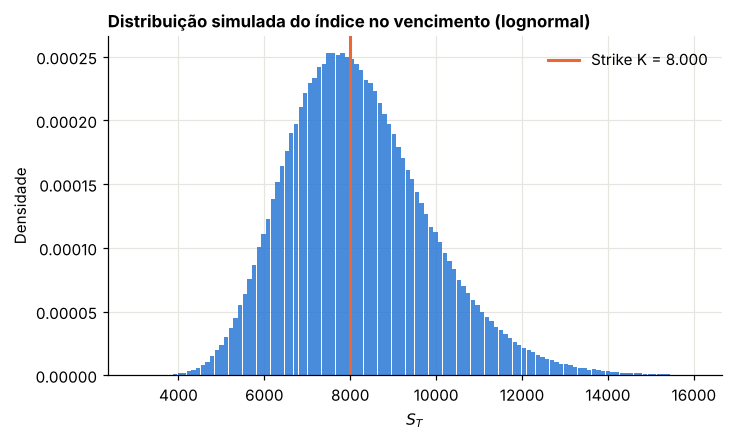

In [7]:
rng = np.random.default_rng(20150211)


def simular_ST(S0, r, sigma, T, n, rng):
    Z = rng.standard_normal(n)
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)


S0, K, T, r, sigma = 8000.0, 8000.0, 1.0, 0.025, 0.20
ST = simular_ST(S0, r, sigma, T, 1_000_000, rng)

teorico = S0 * np.exp(r * T)
sem_ajuste = S0 * np.exp(r * T + 0.5 * sigma**2 * T)
erro_padrao = ST.std(ddof=1) / np.sqrt(ST.size)

tabela(pd.DataFrame([
    {"Quantidade": "Média simulada de S_T", "Valor": ST.mean()},
    {"Quantidade": "Teoria: S0·exp(rT)", "Valor": teorico},
    {"Quantidade": "O que daria sem o termo −σ²/2", "Valor": sem_ajuste},
    {"Quantidade": "Erro-padrão da simulação", "Valor": erro_padrao},
]))
ok(abs(ST.mean() - teorico) < 4 * erro_padrao, "média simulada compatível com S0·exp(rT)")

fig, ax = plt.subplots()
ax.hist(ST, bins=120, range=(3000, 16000), density=True, color=AZUL, alpha=0.85, rwidth=0.92)
ax.axvline(K, color=LARANJA, lw=2, label=f"Strike K = {K:,.0f}".replace(",", "."))
ax.set_title("Distribuição simulada do índice no vencimento (lognormal)")
ax.set_xlabel("$S_T$")
ax.set_ylabel("Densidade")
ax.legend()
plt.show()

Observe a assimetria: a distribuição tem cauda longa à direita. O payoff da call corresponde à parte à direita da linha laranja.

### Passo 3: o estimador de Monte Carlo

Sorteando $I$ cenários, a média dos payoffs descontados aproxima o valor:

$$\hat C_0 = e^{-rT}\,\frac{1}{I}\sum_{i=1}^{I}\max(S_T^{(i)} - K, 0), \qquad \text{erro-padrão} = \frac{\hat s}{\sqrt{I}}.$$

A divisão por $\sqrt{I}$ é o preço do método: para reduzir o erro à metade, é preciso **quadruplicar** o número de cenários.

### Passo 4: a fórmula fechada de Black-Scholes-Merton

No modelo lognormal, aquela integral tem solução exata:

$$C_0 = S_0\,N(d_1) - K e^{-rT} N(d_2)$$

$$d_1 = \frac{\ln(S_0/K) + (r + \tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

em que $N(\cdot)$ é a função de distribuição da normal padrão. Por enquanto é uma caixa-preta; o módulo 5 a deduz por dois caminhos. Mesmo assim, já dá para ler a estrutura:

| Termo | Leitura |
|---|---|
| $N(d_2)$ | probabilidade, sob $Q$, de a opção terminar dentro do dinheiro |
| $K e^{-rT} N(d_2)$ | valor presente do que se espera **pagar** no exercício |
| $S_0 N(d_1)$ | valor presente do que se espera **receber** de índice, quando há exercício |

A put vem da paridade, que deduziremos na Seção 6: $P_0 = K e^{-rT} N(-d_2) - S_0 N(-d_1)$.

### Laboratório 3.2 — Monte Carlo contra a fórmula

In [8]:
def bsm(S, K, T, r, sigma, tipo="call"):
    """Valor BSM de call ou put europeia. Aceita arrays em S e K."""
    S, K = np.asarray(S, float), np.asarray(K, float)
    raiz = sigma * np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / raiz
    d2 = d1 - raiz
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


linhas = []
desconto = np.exp(-r * T)
for k in [6000.0, 7000.0, 8000.0, 9000.0, 10000.0]:
    amostra = desconto * payoff_call(ST, k)
    mc = amostra.mean()
    ep = amostra.std(ddof=1) / np.sqrt(amostra.size)
    fechada = float(bsm(S0, k, T, r, sigma))
    linhas.append({"Strike": k, "Monte Carlo": mc, "Erro-padrão": ep, "BSM": fechada, "Diferença em erros-padrão": (mc - fechada) / ep})
df = pd.DataFrame(linhas)
tabela(df)
ok((df["Diferença em erros-padrão"].abs() < 4).all(), "Monte Carlo e BSM coincidem dentro de 4 erros-padrão")

d2 = (np.log(S0 / K) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
freq = (ST > K).mean()
print("Frequência simulada de S_T > K:", f3(freq), "| N(d2):", f3(norm.cdf(d2)))
ok(abs(freq - norm.cdf(d2)) < 0.002, "N(d2) é a probabilidade neutra ao risco de exercício")

,Strike,Monte Carlo,Erro-padrão,BSM,Diferença em erros-padrão
0,"6.000,000","2.183,426","1,560","2.182,666","0,487"
1,"7.000,000","1.353,073","1,396","1.352,288","0,563"
2,"8.000,000","733,489","1,116","733,033","0,409"
3,"9.000,000","349,737","0,800","349,675","0,078"
4,"10.000,000","149,351","0,526","149,335","0,030"


OK — Monte Carlo e BSM coincidem dentro de 4 erros-padrão
Frequência simulada de S_T > K: 0,511 | N(d2): 0,510
OK — N(d2) é a probabilidade neutra ao risco de exercício


### O que move o valor hoje

São quatro fatores de mercado, além do strike:

1. **Nível do índice.** Quanto mais alto, mais provável terminar acima do strike.
2. **Volatilidade.** Maior oscilação aumenta o valor. Parece estranho, porque risco costuma ser ruim; a explicação vem logo abaixo.
3. **Prazo.** Mais tempo, mais chance de o índice ultrapassar o strike.
4. **Taxa de juros.** Essa exige cuidado, e o Laboratório 3.4 mostra por quê.

### Por que volatilidade aumenta o valor: a convexidade passo a passo

Considere uma call com $K = 100$ e um índice que fecha em $100 + a$ ou $100 - a$, com 50% de chance cada. A média do índice é sempre 100, seja qual for $a$. O payoff médio é:

$$\tfrac12 \max(a, 0) + \tfrac12\max(-a, 0) = \tfrac{a}{2}.$$

Dobrar a dispersão dobra o payoff médio, **sem alterar a média do índice**. O motivo é a assimetria do contrato: o titular fica com os ganhos da alta e não paga pelas perdas da baixa. Em linguagem matemática, para função convexa $h$, a desigualdade de Jensen dá $\mathbb{E}[h(S)] \ge h(\mathbb{E}[S])$, e a diferença cresce com a dispersão.

### Laboratório 3.3 — Os quatro fatores

Variamos um fator de cada vez a partir de um caso-base com $S_0 = 7.900$, $K = 8.000$, $T = 1$, $r = 2{,}5\%$, $\sigma = 20\%$.

OK — call é crescente em S
OK — call é crescente em sigma
OK — call é crescente em T
OK — call é crescente em r


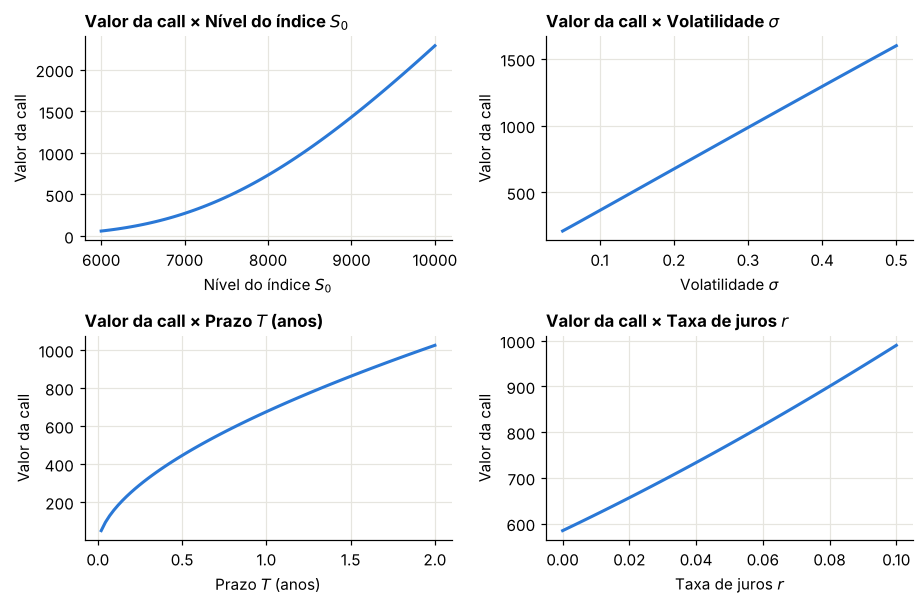

In [9]:
base = dict(S=7900.0, K=8000.0, T=1.0, r=0.025, sigma=0.20)


def varia(par, grade):
    return np.array([float(bsm(**{**base, par: v})) for v in grade])


grades = {
    "S": (np.linspace(6000, 10000, 80), "Nível do índice $S_0$"),
    "sigma": (np.linspace(0.05, 0.50, 80), "Volatilidade $\\sigma$"),
    "T": (np.linspace(0.02, 2.0, 80), "Prazo $T$ (anos)"),
    "r": (np.linspace(0.0, 0.10, 80), "Taxa de juros $r$"),
}

fig, eixos = plt.subplots(2, 2, figsize=(8.5, 5.6), sharey=False)
for ax, (par, (grade, rotulo)) in zip(eixos.ravel(), grades.items()):
    valores = varia(par, grade)
    ax.plot(grade, valores, color=AZUL)
    ax.set_title(f"Valor da call × {rotulo}")
    ax.set_xlabel(rotulo)
    ax.set_ylabel("Valor da call")
    ok(np.all(np.diff(valores) > 0), f"call é crescente em {par}")
plt.tight_layout()
plt.show()

### Laboratório 3.4 — O efeito dos juros tem duas partes

É comum dizer apenas que "os juros descontam o payoff". Se fosse só isso, juros mais altos **reduziriam** o valor da call, mas o gráfico acima mostrou o contrário. Há dois efeitos em sentidos opostos:

$$C_0 = \underbrace{e^{-rT}}_{\text{desconto: cai com } r}\ \times\ \underbrace{\mathbb{E}^Q[\max(S_T - K,0)]}_{\text{cresce com } r,\ \text{pois } \mathbb{E}^Q[S_T] = S_0e^{rT}}$$

Vamos separar os efeitos ao subir $r$ de 2,5% para 5%.

In [10]:
r0, r1 = 0.025, 0.05
args = dict(S=base["S"], K=base["K"], T=base["T"], sigma=base["sigma"])

for tipo in ["call", "put"]:
    v0 = float(bsm(r=r0, tipo=tipo, **args))
    v1 = float(bsm(r=r1, tipo=tipo, **args))
    so_desconto = v0 * np.exp(-(r1 - r0) * args["T"])
    efeito_desc = so_desconto - v0
    efeito_dist = v1 - so_desconto
    tabela(pd.DataFrame([{
        "Opção": tipo, "Valor com r=2,5%": v0, "Efeito do desconto": efeito_desc,
        "Efeito da distribuição": efeito_dist, "Valor com r=5%": v1,
    }]))
    if tipo == "call":
        ok(efeito_desc < 0 < efeito_dist and v1 > v0, "na call, o efeito da distribuição supera o do desconto")
    else:
        ok(efeito_desc < 0 and efeito_dist < 0 and v1 < v0, "na put, os dois efeitos reduzem o valor")

,Opção,"Valor com r=2,5%",Efeito do desconto,Efeito da distribuição,Valor com r=5%
0,call,"675,358","-16,675","114,866","773,549"


OK — na call, o efeito da distribuição supera o do desconto


,Opção,"Valor com r=2,5%",Efeito do desconto,Efeito da distribuição,Valor com r=5%
0,put,"577,837","-14,267","-80,185","483,385"


OK — na put, os dois efeitos reduzem o valor


### Valor intrínseco e valor no tempo

O valor de uma opção se decompõe em:

$$\text{Valor} = \underbrace{\max(S_0 - K, 0)}_{\text{valor intrínseco}} + \underbrace{\text{(diferença)}}_{\text{valor no tempo}}$$

O livro afirma que o valor presente fica sempre acima do intrínseco. Para a **call sem dividendos e com $r \ge 0$**, isso é correto, e dá para demonstrar sem modelo algum.

**Passo 1.** Monte duas carteiras hoje:

- **A:** uma call + $K e^{-rT}$ em renda fixa.
- **B:** uma unidade do índice.

**Passo 2.** Compare os valores em $T$. A renda fixa vira $K$, então:

| Cenário | Carteira A | Carteira B |
|---|---|---|
| $S_T \ge K$ | $(S_T - K) + K = S_T$ | $S_T$ |
| $S_T < K$ | $0 + K = K > S_T$ | $S_T$ |

**Passo 3.** A carteira A paga sempre pelo menos o mesmo que B, logo não pode custar menos: $C_0 + K e^{-rT} \ge S_0$.

**Passo 4.** Portanto $C_0 \ge S_0 - K e^{-rT} \ge S_0 - K$, usando $e^{-rT} \le 1$. Combinado com $C_0 \ge 0$, a call vale pelo menos o intrínseco.

**A afirmação não vale para a put europeia.** Bem dentro do dinheiro, o titular gostaria de receber $K$ logo para aplicar a juros, mas a europeia o obriga a esperar. O laboratório abaixo mostra valor no tempo **negativo**.

> **Errata do livro:** a legenda da Figura 2.2 diz $K = 9.000$, mas o código e o próprio gráfico usam $K = 8.000$.

### Laboratório 3.5 — Valor intrínseco, valor no tempo e o caso da put

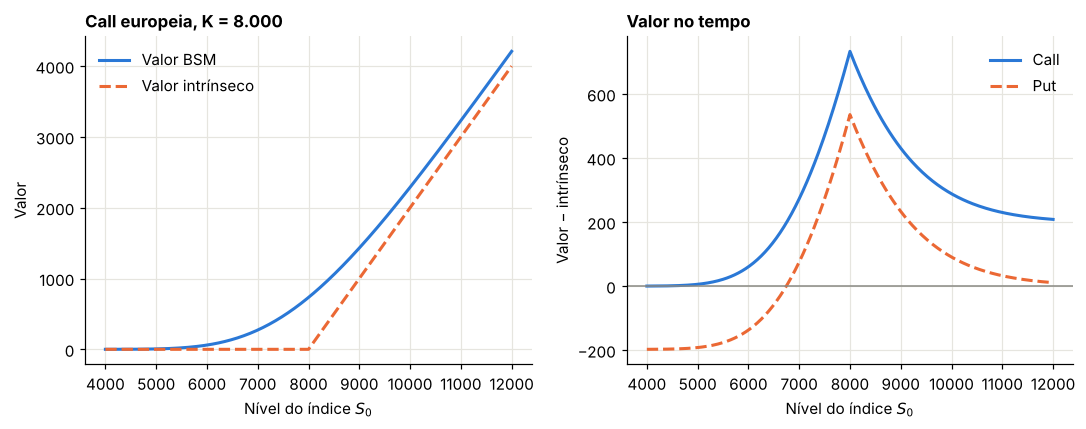

OK — valor no tempo da call é sempre positivo (r > 0, sem dividendos)
OK — put europeia bem dentro do dinheiro tem valor no tempo negativo
Pior valor no tempo da put: -197,400 | limite teórico K(exp(-rT) − 1): -197,521


In [11]:
K, T, r, sigma = 8000.0, 1.0, 0.025, 0.20
S = np.linspace(4000, 12000, 321)

call = bsm(S, K, T, r, sigma, "call")
put = bsm(S, K, T, r, sigma, "put")
tempo_call = call - payoff_call(S, K)
tempo_put = put - payoff_put(S, K)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot(S, call, color=AZUL, label="Valor BSM")
a1.plot(S, payoff_call(S, K), color=LARANJA, ls="--", label="Valor intrínseco")
a1.set_title("Call europeia, K = 8.000")
a1.set_xlabel("Nível do índice $S_0$")
a1.set_ylabel("Valor")
a1.legend()

a2.plot(S, tempo_call, color=AZUL, label="Call")
a2.plot(S, tempo_put, color=LARANJA, ls="--", label="Put")
a2.axhline(0, color=CINZA, lw=1)
a2.set_title("Valor no tempo")
a2.set_xlabel("Nível do índice $S_0$")
a2.set_ylabel("Valor − intrínseco")
a2.legend()
plt.tight_layout()
plt.show()

ok(np.all(tempo_call > 0), "valor no tempo da call é sempre positivo (r > 0, sem dividendos)")
ok(tempo_put.min() < 0, "put europeia bem dentro do dinheiro tem valor no tempo negativo")
print("Pior valor no tempo da put:", f3(tempo_put.min()), "| limite teórico K(exp(-rT) − 1):", f3(K * (np.exp(-r * T) - 1)))

---
## 4. Vanilla, exóticos e o que é "o mercado"

**Livro: §2.2**

Os instrumentos se dividem em dois grupos:

| | Vanilla | Exótico |
|---|---|---|
| Exemplos | Call e put europeias, listadas | Barreira, asiática, lookback, cliente sob medida |
| Liquidez | Cotação frequente | Pouca ou nenhuma negociação |
| Preço | **Observado** | Precisa ser **calculado** |

Aqui entra a ideia central do curso. Na avaliação teórica, o caminho é:

$$\text{modelo} + \text{parâmetros} \longrightarrow \text{preços}.$$

Na **avaliação baseada em mercado**, o caminho é invertido para os vanilla:

$$\text{preços observados dos vanilla} \longrightarrow \text{parâmetros (calibração)} \longrightarrow \text{preço do exótico}.$$

**Exigência mínima:** qualquer modelo usado para avaliar um exótico deve reproduzir bem os vanilla do mesmo ativo. É uma condição necessária, mas não suficiente, como a Seção 7 vai mostrar.

Ao escolher o modelo, há duas camadas de decisão:

- **Qualitativa:** que comportamento o processo precisa ter? Um índice de ações tende a crescer no longo prazo; juros e volatilidade tendem a voltar a um nível de equilíbrio.
- **Quantitativa:** dada a forma do modelo, quais parâmetros usar? Em finanças não há constantes universais como na física. Essa liberdade é justamente o que permite calibrar.

### Laboratório 4.1 — Por que exóticos exigem o caminho inteiro

Três trajetórias terminam **no mesmo ponto**. Para uma opção europeia, são idênticas. Para exóticos, não. Isso explica por que modelos que acertam a distribuição em $T$ podem errar exóticos: o exótico depende da distribuição **da trajetória**.

,Trajetória,S_T,Call europeia,Barreira knock-out em 80,Asiática (média),Lookback (S_T − mínimo)
0,A: subida suave,"110,000","10,000","10,000","5,000","10,000"
1,B: queda forte e recuperação,"110,000","10,000","0,000","0,000","35,000"
2,C: alta forte e devolução,"110,000","10,000","10,000","19,000","10,000"


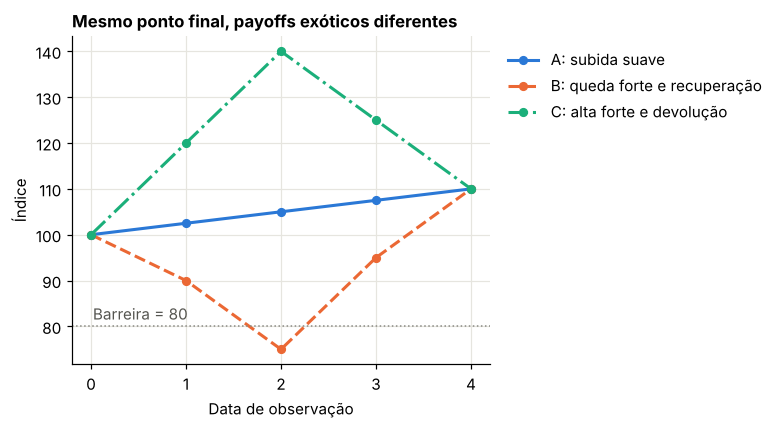

OK — a call europeia não distingue as trajetórias
OK — os exóticos distinguem as trajetórias


In [12]:
caminhos = {
    "A: subida suave": np.array([100.0, 102.5, 105.0, 107.5, 110.0]),
    "B: queda forte e recuperação": np.array([100.0, 90.0, 75.0, 95.0, 110.0]),
    "C: alta forte e devolução": np.array([100.0, 120.0, 140.0, 125.0, 110.0]),
}
K_ex, H = 100.0, 80.0

linhas = []
for nome, p in caminhos.items():
    linhas.append({
        "Trajetória": nome,
        "S_T": p[-1],
        "Call europeia": max(p[-1] - K_ex, 0.0),
        "Barreira knock-out em 80": max(p[-1] - K_ex, 0.0) * float(p.min() > H),
        "Asiática (média)": max(p.mean() - K_ex, 0.0),
        "Lookback (S_T − mínimo)": p[-1] - p.min(),
    })
df = pd.DataFrame(linhas)
tabela(df)

fig, ax = plt.subplots()
for (nome, p), cor, estilo in zip(caminhos.items(), [AZUL, LARANJA, VERDE], ["-", "--", "-."]):
    ax.plot(p, color=cor, ls=estilo, marker="o", markersize=5, label=nome)
ax.axhline(H, color=CINZA, lw=1, ls=":")
ax.text(0.02, H + 1.5, "Barreira = 80", color="#555550")
ax.set_title("Mesmo ponto final, payoffs exóticos diferentes")
ax.set_xlabel("Data de observação")
ax.set_ylabel("Índice")
ax.set_xticks(range(5))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

ok(df["Call europeia"].nunique() == 1, "a call europeia não distingue as trajetórias")
ok(df["Barreira knock-out em 80"].nunique() > 1 and df["Asiática (média)"].nunique() > 1, "os exóticos distinguem as trajetórias")

---
## 5. Os riscos que movem uma opção

**Livro: §2.3**

| Risco | O que é | Onde entra no curso |
|---|---|---|
| **Preço** | oscilação do índice | Delta; módulo 5 |
| **Volatilidade** | a própria volatilidade é aleatória | Heston; módulos 11-14 |
| **Salto** | quedas abruptas, que quebram o hedge | Merton; módulos 10 e 11 |
| **Juros** | afetam desconto e drift | CIR; módulos 11 e 13 |
| **Correlação** | co-movimentos que mudam em estresse | Parâmetro $\rho$ do Heston; módulo 11 |
| **Liquidez** | hedge pode não ser executável | Fora do escopo do livro |
| **Crédito** | default de emissor | Pouco relevante em índice; fora do escopo |

Além desses, dois riscos não são de mercado: o **risco de modelo** (o modelo cobre o fator, mas de forma errada) e o **risco operacional** (a estratégia está certa, mas a execução falha).

### Laboratório 5.1 — Reprecificação completa contra aproximação linear

Em risco, é tentador usar a aproximação de primeira ordem:

$$\Delta V \approx \frac{\partial V}{\partial S}\,dS + \frac{\partial V}{\partial \sigma}\,d\sigma + \frac{\partial V}{\partial r}\,dr + \frac{\partial V}{\partial t}\,dt.$$

Calculamos as derivadas por diferenças finitas e comparamos com a reprecificação completa, em cenários pequenos e grandes. Fique atento ao erro no cenário de crash.

In [13]:
b = dict(S=8000.0, K=8000.0, T=1.0, r=0.025, sigma=0.20)
v0 = float(bsm(**b))


def derivada(par, h):
    return float(bsm(**{**b, par: b[par] + h}) - bsm(**{**b, par: b[par] - h})) / (2 * h)


dV = {"S": derivada("S", 1.0), "sigma": derivada("sigma", 1e-4), "r": derivada("r", 1e-4), "T": derivada("T", 1e-4)}

cenarios = {
    "Índice −1%": dict(S=-80.0),
    "Índice −10%": dict(S=-800.0),
    "Volatilidade +5 p.p.": dict(sigma=0.05),
    "Juros +100 bps": dict(r=0.01),
    "Passa 1 mês": dict(T=-1 / 12),
    "Crash: índice −20%, vol +15 p.p.": dict(S=-1600.0, sigma=0.15),
}

linhas = []
for nome, choque in cenarios.items():
    novo = {k: b[k] + choque.get(k, 0.0) for k in b}
    completa = float(bsm(**novo)) - v0
    linear = sum(dV[k] * d for k, d in choque.items())
    linhas.append({"Cenário": nome, "Reprecificação completa": completa, "Aprox. linear": linear, "Erro da aprox.": linear - completa})
df = pd.DataFrame(linhas)
print("Valor inicial da call:", f3(v0))
tabela(df)

erro = df.set_index("Cenário")["Erro da aprox."].abs()
ok(erro["Crash: índice −20%, vol +15 p.p."] > 5 * erro["Índice −1%"], "o erro da aproximação linear explode no cenário de crash")

Valor inicial da call: 733,033


,Cenário,Reprecificação completa,Aprox. linear,Erro da aprox.
0,Índice −1%,"-46,337","-47,121","-0,783"
1,Índice −10%,"-389,352","-471,208","-81,856"
2,Volatilidade +5 p.p.,"155,621","155,588","-0,032"
3,Juros +100 bps,"40,365","39,790","-0,574"
4,Passa 1 mês,"-34,818","-34,221","0,597"
5,"Crash: índice −20%, vol +15 p.p.","-295,955","-475,652","-179,697"


OK — o erro da aproximação linear explode no cenário de crash


**Leitura.** A aproximação linear vai bem para movimentos pequenos e piora muito em movimentos grandes, porque ignora a curvatura (gama) e as derivadas cruzadas. É por isso que stress de carteira de opções se faz com reprecificação completa.

---
## 6. Hedge: estático e dinâmico

**Livro: §2.4**

O lançador recebeu o prêmio e agora tem uma obrigação incerta. Ele quer montar algo que pague exatamente o que deve, zerando o risco. Há dois tipos de programa:

- **Estático:** monta-se no início e não se mexe mais, em geral usando outras opções.
- **Dinâmico:** ajusta-se a carteira ao longo do tempo, em geral usando o próprio ativo-objeto.

### Hedge estático: a paridade put-call

Voltamos à identidade da Seção 1: call comprada + put vendida paga $S_T - K$ em qualquer cenário. Esse mesmo payoff se obtém com uma unidade do índice e um empréstimo de $K e^{-rT}$. Dois investimentos com o mesmo payoff têm o mesmo custo, logo:

$$C_0 - P_0 = S_0 - K e^{-rT}.$$

É uma relação **sem modelo**: não depende de volatilidade nem de lognormalidade.

### Hedge dinâmico: o algoritmo

Vendemos uma call e recebemos o prêmio. Em cada data de rebalanceamento:

1. calculamos o delta $N(d_1)$ com o prazo restante;
2. compramos ou vendemos índice para chegar nesse delta, financiando pela conta-caixa;
3. a conta-caixa rende $r$ até a próxima data.

No vencimento, zeramos tudo e pagamos o payoff. O saldo é o **erro de hedge** (P&L).

A teoria diz que, sob as hipóteses do BSM e com rebalanceamento contínuo, esse erro é **zero**. Vamos testar o que acontece com rebalanceamento discreto, e depois fora das hipóteses.

### Laboratório 6.1 — Simulador de trajetórias e delta hedge

Criamos um único simulador que serve para os dois mundos, com e sem saltos. O número de saltos em cada passo é Poisson, com intensidade $\lambda$, e cada salto tem log-tamanho normal $N(\mu_J, \delta_J^2)$. O termo $\lambda\kappa$, com $\kappa = e^{\mu_J + \delta_J^2/2} - 1$, compensa o crescimento médio causado pelos saltos, para que o drift total continue igual a $\mu$.

In [14]:
def simular_caminhos(S0, mu, sigma, T, M, I, rng, salto=None):
    """Trajetórias em M passos e I cenários. salto = (lambda, mu_J, delta_J) ou None."""
    dt = T / M
    Z = rng.standard_normal((M, I))
    lam, comp, J = 0.0, 0.0, 0.0
    if salto is not None:
        lam, mu_j, delta_j = salto
        comp = lam * (np.exp(mu_j + 0.5 * delta_j**2) - 1)
        N = rng.poisson(lam * dt, (M, I))
        J = N * mu_j + np.sqrt(N) * delta_j * rng.standard_normal((M, I))
    incrementos = (mu - comp - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z + J
    log_S = np.vstack([np.zeros(I), np.cumsum(incrementos, axis=0)])
    return S0 * np.exp(log_S)


def delta_call(S, K, tau, r, sigma):
    return norm.cdf((np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau)))


def pnl_delta_hedge(trajetorias, K, T, r, sigma_h, N):
    """P&L no vencimento de vender a call ao preço BSM e fazer delta hedge com N rebalanceamentos."""
    M = trajetorias.shape[0] - 1
    passo = M // N
    assert passo * N == M, "N precisa dividir M"
    S = trajetorias[::passo]
    dt = T / N

    delta = delta_call(S[0], K, T, r, sigma_h)
    caixa = float(bsm(S[0, 0], K, T, r, sigma_h)) - delta * S[0]
    for i in range(1, N):
        caixa *= np.exp(r * dt)
        novo = delta_call(S[i], K, T - i * dt, r, sigma_h)
        caixa -= (novo - delta) * S[i]
        delta = novo
    caixa *= np.exp(r * dt)
    return caixa + delta * S[N] - payoff_call(S[N], K)


S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.025, 0.20
M, I = 252, 40_000
Ns = [6, 12, 21, 42, 84, 252]

rng = np.random.default_rng(7)
mundo_bsm = simular_caminhos(S0, r + 0.06, sigma, T, M, I, rng)

linhas = []
for n in Ns:
    pnl = pnl_delta_hedge(mundo_bsm, K, T, r, sigma, n)
    linhas.append({"Rebalanceamentos N": n, "P&L médio": pnl.mean(), "Desvio-padrão do P&L": pnl.std(ddof=1), "Pior caso": pnl.min()})
res_bsm = pd.DataFrame(linhas)
print("Prêmio recebido:", f3(float(bsm(S0, K, T, r, sigma))))
tabela(res_bsm)

inclinacao = np.polyfit(np.log(res_bsm["Rebalanceamentos N"]), np.log(res_bsm["Desvio-padrão do P&L"]), 1)[0]
print("Inclinação log-log do erro de hedge:", f3(inclinacao), "(teoria: −0,500)")
ok(-0.62 < inclinacao < -0.38, "erro de hedge cai na taxa aproximada de 1/√N")
ultimo = res_bsm.iloc[-1]
ok(abs(ultimo["P&L médio"]) < 4 * ultimo["Desvio-padrão do P&L"] / np.sqrt(I), "P&L médio do hedge diário compatível com zero, apesar de μ ≠ r")

Prêmio recebido: 9,163


,Rebalanceamentos N,P&L médio,Desvio-padrão do P&L,Pior caso
0,6,"-0,041","2,685","-18,396"
1,12,"-0,022","1,934","-18,193"
2,21,"-0,017","1,467","-10,443"
3,42,"-0,007","1,044","-7,659"
4,84,"-0,002","0,746","-4,955"
5,252,"-0,001","0,435","-2,610"


Inclinação log-log do erro de hedge: -0,488 (teoria: −0,500)
OK — erro de hedge cai na taxa aproximada de 1/√N
OK — P&L médio do hedge diário compatível com zero, apesar de μ ≠ r


**Duas observações importantes.**

1. O erro cai com $1/\sqrt{N}$. Para reduzi-lo à metade, é preciso rebalancear quatro vezes mais, e na prática cada rebalanceamento tem custo.
2. As trajetórias foram simuladas com retorno médio $\mu = r + 6\%$, e não $r$. O P&L médio continuou compatível com zero. É a mesma lição da Seção 2: **a tendência do ativo não entra no valor da opção**.

### Laboratório 6.2 — E quando existem saltos?

Agora o índice pode saltar. Fazemos o mesmo hedge, usando no delta a volatilidade total equivalente $\sigma_h = \sqrt{\sigma^2 + \lambda(\mu_J^2 + \delta_J^2)}$.

Volatilidade total equivalente: 0,218


,Rebalanceamentos N,P&L médio,Desvio-padrão do P&L,Pior caso
0,6,"0,178","4,507","-44,772"
1,12,"0,206","4,385","-45,228"
2,21,"0,237","4,337","-37,370"
3,42,"0,245","4,318","-35,194"
4,84,"0,249","4,311","-35,494"
5,252,"0,254","4,299","-34,271"


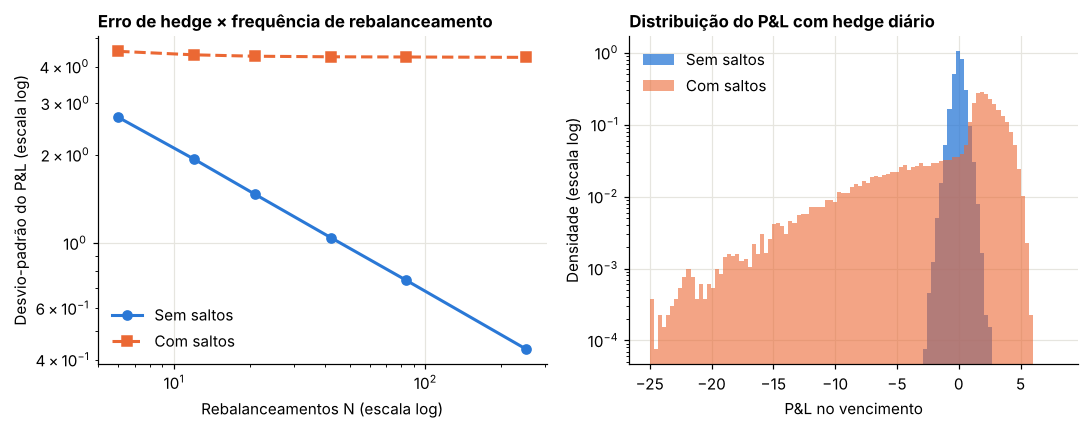

Razão entre os erros de hedge diário (com/sem saltos): 9,890
OK — com saltos, o erro de hedge diário é muito maior
OK — com saltos, rebalancear mais ajuda bem menos


In [15]:
salto = (0.6, -0.18, 0.12)
sigma_dif = 0.14
lam, mu_j, delta_j = salto
sigma_h = np.sqrt(sigma_dif**2 + lam * (mu_j**2 + delta_j**2))

rng = np.random.default_rng(8)
mundo_saltos = simular_caminhos(S0, r + 0.06, sigma_dif, T, M, I, rng, salto=salto)

linhas = []
for n in Ns:
    pnl = pnl_delta_hedge(mundo_saltos, K, T, r, sigma_h, n)
    linhas.append({"Rebalanceamentos N": n, "P&L médio": pnl.mean(), "Desvio-padrão do P&L": pnl.std(ddof=1), "Pior caso": pnl.min()})
res_saltos = pd.DataFrame(linhas)
print("Volatilidade total equivalente:", f3(sigma_h))
tabela(res_saltos)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.loglog(res_bsm["Rebalanceamentos N"], res_bsm["Desvio-padrão do P&L"], color=AZUL, marker="o", markersize=6, label="Sem saltos")
a1.loglog(res_saltos["Rebalanceamentos N"], res_saltos["Desvio-padrão do P&L"], color=LARANJA, marker="s", markersize=6, ls="--", label="Com saltos")
a1.set_title("Erro de hedge × frequência de rebalanceamento")
a1.set_xlabel("Rebalanceamentos N (escala log)")
a1.set_ylabel("Desvio-padrão do P&L (escala log)")
a1.legend()

p1 = pnl_delta_hedge(mundo_bsm, K, T, r, sigma, 252)
p2 = pnl_delta_hedge(mundo_saltos, K, T, r, sigma_h, 252)
faixa = (-25, 8)
a2.hist(p1, bins=100, range=faixa, density=True, color=AZUL, alpha=0.75, label="Sem saltos")
a2.hist(p2, bins=100, range=faixa, density=True, color=LARANJA, alpha=0.6, label="Com saltos")
a2.set_yscale("log")
a2.set_title("Distribuição do P&L com hedge diário")
a2.set_xlabel("P&L no vencimento")
a2.set_ylabel("Densidade (escala log)")
a2.legend()
plt.tight_layout()
plt.show()

razao = res_saltos.iloc[-1]["Desvio-padrão do P&L"] / res_bsm.iloc[-1]["Desvio-padrão do P&L"]
print("Razão entre os erros de hedge diário (com/sem saltos):", f3(razao))
ok(razao > 3, "com saltos, o erro de hedge diário é muito maior")
queda_bsm = res_bsm.iloc[0]["Desvio-padrão do P&L"] / res_bsm.iloc[-1]["Desvio-padrão do P&L"]
queda_saltos = res_saltos.iloc[0]["Desvio-padrão do P&L"] / res_saltos.iloc[-1]["Desvio-padrão do P&L"]
ok(queda_saltos < queda_bsm / 2, "com saltos, rebalancear mais ajuda bem menos")

**Por que o hedge não converge?** Um salto acontece entre dois rebalanceamentos, de forma que nenhuma frequência consegue antecipá-lo. O mercado é **incompleto**: uma única fonte de hedge (o índice) não dá conta de dois tipos de risco. Só resta **minimizar** o erro, tema do módulo 16.

---
## 7. O processo completo em miniatura

**Livro: §2.5**

O resto do curso aprofunda estas seis etapas. Vamos percorrer todas agora, em versão simples:

| Etapa | Pergunta | Aqui | Módulos |
|---|---|---|---|
| 1. Realidade de mercado | Como o mercado se comporta? | Superfície com assimetria | 2 |
| 2. Modelo | Qual modelo representa isso? | BSM contra Merton (saltos) | 3-5, 11 |
| 3. Avaliar vanilla | Como precificar rápido? | Fórmulas fechadas | 5-8 |
| 4. Calibrar | Quais parâmetros? | Mínimos quadrados | 13, 14 |
| 5. Avaliar exótico | Quanto vale o produto? | Monte Carlo de uma barreira | 12, 15 |
| 6. Hedge | Como proteger? | Delta por reprecificação | 16 |

### Etapa 1 — O mercado sintético

O livro usa cotações reais do EURO STOXX 50, distribuídas com os scripts na plataforma do autor. Aqui geramos um **mercado sintético** a partir de um modelo conhecido, com um pequeno ruído. A vantagem didática é grande: **sabemos a resposta certa** e podemos verificar se a calibração a recupera.

### Etapas 2 e 3 — Dois modelos

**Modelo A (BSM):** volatilidade constante.

**Modelo B (Merton 1976):** BSM mais saltos. O preço tem uma lógica simples. **Condicionado** a ter havido exatamente $n$ saltos até $T$, o log-retorno é normal, ou seja, voltamos ao BSM com parâmetros ajustados:

$$\sigma_n^2 = \sigma^2 + \frac{n\,\delta_J^2}{T}, \qquad r_n = r - \lambda\kappa + \frac{n\ln(1+\kappa)}{T}.$$

O valor é a média desses preços BSM, ponderada pela probabilidade de cada $n$, com uma intensidade ajustada $\lambda' = \lambda(1+\kappa)$:

$$C^{M76}_0 = \sum_{n=0}^{\infty} \frac{e^{-\lambda' T}(\lambda' T)^n}{n!}\ C^{BSM}(S_0, K, T, r_n, \sigma_n).$$

A dedução completa está no módulo 10. Abaixo, o preço é conferido por Monte Carlo.

In [16]:
def merton_call(S, K, T, r, sigma, lam, mu_j, delta_j, n_max=60):
    """Call europeia em Merton (1976), como mistura Poisson de preços BSM."""
    kappa = np.exp(mu_j + 0.5 * delta_j**2) - 1
    lam_q = lam * (1 + kappa)
    total = 0.0
    for n in range(n_max):
        peso = poisson.pmf(n, lam_q * T)
        s_n = np.sqrt(sigma**2 + n * delta_j**2 / T)
        r_n = r - lam * kappa + n * np.log1p(kappa) / T
        total = total + peso * bsm(S, K, T, r_n, s_n)
    return total


verdade = dict(sigma=0.14, lam=0.6, mu_j=-0.18, delta_j=0.12)
S0, r = 100.0, 0.025

rng = np.random.default_rng(99)
teste = simular_caminhos(S0, r, verdade["sigma"], 1.0, 1, 1_000_000, rng, salto=(verdade["lam"], verdade["mu_j"], verdade["delta_j"]))[-1]
amostra = np.exp(-r) * payoff_call(teste, 100.0)
mc, ep = amostra.mean(), amostra.std(ddof=1) / np.sqrt(amostra.size)
fechada = float(merton_call(S0, 100.0, 1.0, r, **verdade))
print("Merton fechada:", f3(fechada), "| Monte Carlo:", f3(mc), "| erro-padrão:", f3(ep))
ok(abs(fechada - mc) < 4 * ep, "fórmula de Merton confere com Monte Carlo")

prazos = [0.25, 0.5, 1.0]
strikes = np.array([80.0, 85.0, 90.0, 95.0, 100.0, 105.0, 110.0, 115.0, 120.0])
rng = np.random.default_rng(2015)
ruido_rel = 0.003

cotacoes = []
for t_ in prazos:
    precos = merton_call(S0, strikes, t_, r, **verdade) * (1 + rng.normal(0, ruido_rel, strikes.size))
    cotacoes += [{"T": t_, "K": k, "preco": p} for k, p in zip(strikes, precos)]
mercado = pd.DataFrame(cotacoes)
print("Cotações sintéticas:", len(mercado))

Merton fechada: 9,426 | Monte Carlo: 9,429 | erro-padrão: 0,013
OK — fórmula de Merton confere com Monte Carlo
Cotações sintéticas: 27


### Etapa 4 — Calibração

**Volatilidade implícita.** Em vez de falar em preços, o mercado cota a volatilidade que, colocada no BSM, reproduz o preço observado. Inverter essa fórmula já é uma calibração de um único parâmetro. Como a call é crescente em $\sigma$, a raiz é única e podemos achá-la com o método de Brent.

**Modelo A:** escolhemos $\sigma$ para acertar a call ATM de 1 ano exatamente.

**Modelo B:** temos 4 parâmetros e 27 cotações, então o problema é minimizar os erros ao quadrado,

$$\min_{\sigma, \lambda, \mu_J, \delta_J}\ \sum_{i=1}^{27}\big[C^{M76}(K_i, T_i; \sigma,\lambda,\mu_J,\delta_J) - C_i^{\text{mercado}}\big]^2.$$

Esse problema pode ter mínimos locais, então partimos de vários pontos iniciais e ficamos com o melhor. O módulo 13 trata o tema com o devido cuidado.

RMSE por ponto inicial: ['0,029', '0,029', '0,029', '0,029']


,Parâmetro,Verdadeiro,Calibrado
0,σ,"0,140","0,143"
1,λ,"0,600","0,442"
2,μ_J,"-0,180","-0,226"
3,δ_J,"0,120","0,099"


,Modelo,σ,RMSE em preço
0,"A: BSM, calibrado só no ATM 1 ano","0,207","0,449"
1,"B: Merton, calibrado em tudo","0,143","0,029"


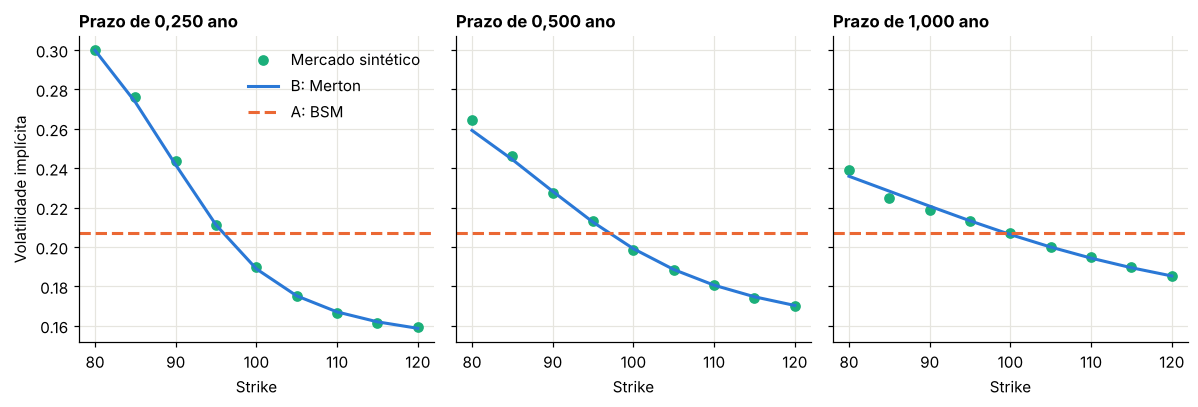

OK — modelo A reproduz exatamente o ATM de 1 ano
OK — modelo B ajusta a superfície muito melhor que o A
OK — há skew: strikes baixos têm volatilidade implícita maior


In [17]:
def vol_implicita(preco, S, K, T, r):
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-4, 3.0)


mercado["vol_impl"] = [vol_implicita(l.preco, S0, l.K, l.T, r) for l in mercado.itertuples()]

atm_1a = mercado.query("T == 1.0 and K == 100.0")["preco"].iloc[0]
sigma_a = vol_implicita(atm_1a, S0, 100.0, 1.0, r)


def erros_b(x):
    sig, lam, mj, dj = x
    saida = []
    for t_, g in mercado.groupby("T"):
        saida.append(merton_call(S0, g["K"].values, t_, r, sig, lam, mj, dj, n_max=30) - g["preco"].values)
    return np.concatenate(saida)


limites = ([0.01, 0.0, -0.6, 0.001], [0.6, 3.0, 0.1, 0.5])
partidas = [[0.20, 0.3, -0.10, 0.10], [0.12, 1.0, -0.20, 0.20], [0.25, 0.1, -0.30, 0.05], [0.10, 2.0, -0.05, 0.15]]
ajustes = [least_squares(erros_b, x0, bounds=limites) for x0 in partidas]
melhor = min(ajustes, key=lambda a: a.cost)
print("RMSE por ponto inicial:", [f3(float(np.sqrt(np.mean(a.fun**2)))) for a in ajustes])

calib = dict(zip(["sigma", "lam", "mu_j", "delta_j"], melhor.x))
tabela(pd.DataFrame({
    "Parâmetro": ["σ", "λ", "μ_J", "δ_J"],
    "Verdadeiro": [float(verdade[k]) for k in calib],
    "Calibrado": [float(v) for v in calib.values()],
}))

mercado["modelo_a"] = [float(bsm(S0, l.K, l.T, r, sigma_a)) for l in mercado.itertuples()]
mercado["modelo_b"] = [float(merton_call(S0, l.K, l.T, r, **calib)) for l in mercado.itertuples()]
mercado["vi_b"] = [vol_implicita(l.modelo_b, S0, l.K, l.T, r) for l in mercado.itertuples()]

rmse = lambda col: float(np.sqrt(np.mean((mercado[col] - mercado["preco"]) ** 2)))
tabela(pd.DataFrame([
    {"Modelo": "A: BSM, calibrado só no ATM 1 ano", "σ": sigma_a, "RMSE em preço": rmse("modelo_a")},
    {"Modelo": "B: Merton, calibrado em tudo", "σ": calib["sigma"], "RMSE em preço": rmse("modelo_b")},
]))

fig, eixos = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, t_ in zip(eixos, prazos):
    g = mercado[mercado["T"] == t_]
    ax.plot(g["K"], g["vol_impl"], "o", color=VERDE, markersize=6, label="Mercado sintético")
    ax.plot(g["K"], g["vi_b"], color=AZUL, label="B: Merton")
    ax.axhline(sigma_a, color=LARANJA, ls="--", label="A: BSM")
    ax.set_title(f"Prazo de {f3(t_)} ano")
    ax.set_xlabel("Strike")
eixos[0].set_ylabel("Volatilidade implícita")
eixos[0].legend()
plt.tight_layout()
plt.show()

ok(abs(float(bsm(S0, 100.0, 1.0, r, sigma_a)) - atm_1a) < 1e-8, "modelo A reproduz exatamente o ATM de 1 ano")
ok(rmse("modelo_b") < rmse("modelo_a") / 5, "modelo B ajusta a superfície muito melhor que o A")
ok(mercado.query("T == 0.25").sort_values("K")["vol_impl"].iloc[0] > mercado.query("T == 0.25 and K == 100.0")["vol_impl"].iloc[0], "há skew: strikes baixos têm volatilidade implícita maior")

O BSM é uma reta horizontal; o mercado tem **skew** (a volatilidade implícita sobe nos strikes baixos). Esse é o primeiro fato estilizado que o módulo 2 vai explorar.

**Olhe também a tabela de parâmetros.** O ajuste em preço é excelente e os quatro pontos iniciais chegam ao mesmo RMSE, mas $\lambda$, $\mu_J$ e $\delta_J$ não coincidem com os verdadeiros. Combinações diferentes de frequência e tamanho de salto geram preços quase iguais, e o ruído basta para deslocar a solução. Esse é o problema da **identificabilidade**: um bom ajuste não prova que os parâmetros estão certos.

### Etapa 5 — Avaliar um exótico

Um **down-and-out call** é uma call que **deixa de existir** se o índice tocar a barreira $H$ em qualquer data até o vencimento. Aqui, $K = 100$, $H = 90$, $T = 1$, monitoramento diário.

Antes de usar a simulação, validamos o simulador: em BSM, com barreira contínua, existe solução fechada,

$$C_{DO} = C(S_0, K) - \Big(\frac{H}{S_0}\Big)^{2r/\sigma^2 - 1}\, C\Big(\frac{H^2}{S_0}, K\Big),$$

e o monitoramento discreto se aproxima deslocando a barreira: $\tilde H = H e^{-0{,}5826\,\sigma\sqrt{\Delta t}}$ (Broadie, Glasserman e Kou, 1997).

### Etapa 6 — Hedge

Se temos como calcular o preço, temos como calcular o hedge. O delta sai de reprecificar com $S_0$ deslocado em $\pm 1\%$. Há um atalho útil: como $S_t$ é proporcional a $S_0$, basta multiplicar as **mesmas** trajetórias, sem nova simulação. Isso elimina quase todo o ruído da diferença.

In [18]:
def down_and_out_fechada(S, K, H, T, r, sigma):
    return float(bsm(S, K, T, r, sigma) - (H / S) ** (2 * r / sigma**2 - 1) * bsm(H**2 / S, K, T, r, sigma))


def avaliar_exoticos(traj, K, H, T, r, escala=1.0):
    """Valor por Monte Carlo da barreira e da put 80, para S0 multiplicado por 'escala'."""
    S = traj * escala
    desconto = np.exp(-r * T)
    vivo = S.min(axis=0) > H
    bar = desconto * payoff_call(S[-1], K) * vivo
    put = desconto * payoff_put(S[-1], 80.0)
    return bar.mean(), bar.std(ddof=1) / np.sqrt(bar.size), put.mean()


K_b, H_b, T_b, M_b, I_b = 100.0, 90.0, 1.0, 252, 100_000

rng = np.random.default_rng(31)
traj_a = simular_caminhos(S0, r, sigma_a, T_b, M_b, I_b, rng)
traj_b = simular_caminhos(S0, r, calib["sigma"], T_b, M_b, I_b, rng, salto=(calib["lam"], calib["mu_j"], calib["delta_j"]))
traj_v = simular_caminhos(S0, r, verdade["sigma"], T_b, M_b, I_b, rng, salto=(verdade["lam"], verdade["mu_j"], verdade["delta_j"]))

H_ajustada = H_b * np.exp(-0.5826 * sigma_a * np.sqrt(T_b / M_b))
referencia = down_and_out_fechada(S0, K_b, H_ajustada, T_b, r, sigma_a)
bar_a, ep_a, _ = avaliar_exoticos(traj_a, K_b, H_b, T_b, r)
print("Validação BSM → fechada com barreira ajustada:", f3(referencia), "| Monte Carlo:", f3(bar_a), "| erro-padrão:", f3(ep_a))
ok(abs(referencia - bar_a) < 4 * ep_a, "simulador da barreira confere com a solução fechada")

linhas = []
for nome, traj, atm in [
    ("A: BSM", traj_a, float(bsm(S0, 100.0, 1.0, r, sigma_a))),
    ("B: Merton calibrado", traj_b, float(merton_call(S0, 100.0, 1.0, r, **calib))),
    ("Verdade: modelo gerador", traj_v, float(merton_call(S0, 100.0, 1.0, r, **verdade))),
]:
    v, ep, put80 = avaliar_exoticos(traj, K_b, H_b, T_b, r)
    up = avaliar_exoticos(traj, K_b, H_b, T_b, r, 1.01)[0]
    dn = avaliar_exoticos(traj, K_b, H_b, T_b, r, 0.99)[0]
    linhas.append({"Modelo": nome, "Call ATM 1 ano": atm, "Put 80": put80, "Down-and-out": v, "Erro-padrão": ep, "Delta da barreira": (up - dn) / (2 * 0.01 * S0)})
res = pd.DataFrame(linhas)
tabela(res)

linhas = []
for h in [80.0, 85.0, 90.0]:
    va, ea, _ = avaliar_exoticos(traj_a, K_b, h, T_b, r)
    vv, ev, _ = avaliar_exoticos(traj_v, K_b, h, T_b, r)
    linhas.append({"Barreira H": h, "A: BSM": va, "Verdade": vv, "Diferença": va - vv, "Erro-padrão da diferença": float(np.hypot(ea, ev))})
sens = pd.DataFrame(linhas)
tabela(sens)
del traj_a, traj_b, traj_v

r_ = res.set_index("Modelo")
ok(abs(r_.loc["A: BSM", "Call ATM 1 ano"] - r_.loc["Verdade: modelo gerador", "Call ATM 1 ano"]) < 0.1, "os modelos concordam no vanilla ATM")
ok(abs(r_.loc["A: BSM", "Put 80"] - r_.loc["Verdade: modelo gerador", "Put 80"]) > 0.4, "o BSM erra a put fora do dinheiro")
ok(abs(r_.loc["A: BSM", "Down-and-out"] - r_.loc["Verdade: modelo gerador", "Down-and-out"]) > 4 * np.hypot(r_.loc["A: BSM", "Erro-padrão"], r_.loc["Verdade: modelo gerador", "Erro-padrão"]), "o BSM erra o exótico")
ok(abs(sens["Diferença"]).is_monotonic_increasing, "o erro do BSM cresce quando a barreira se aproxima do spot")
ok(abs(r_.loc["B: Merton calibrado", "Down-and-out"] - r_.loc["Verdade: modelo gerador", "Down-and-out"]) < abs(r_.loc["A: BSM", "Down-and-out"] - r_.loc["Verdade: modelo gerador", "Down-and-out"]), "o modelo calibrado fica mais perto da verdade no exótico")

Validação BSM → fechada com barreira ajustada: 7,864 | Monte Carlo: 7,749 | erro-padrão: 0,045
OK — simulador da barreira confere com a solução fechada


,Modelo,Call ATM 1 ano,Put 80,Down-and-out,Erro-padrão,Delta da barreira
0,A: BSM,"9,439","1,029","7,749","0,045","0,737"
1,B: Merton calibrado,"9,407","1,565","8,862","0,040","0,722"
2,Verdade: modelo gerador,"9,426","1,546","8,889","0,040","0,713"


,Barreira H,A: BSM,Verdade,Diferença,Erro-padrão da diferença
0,"80,000","9,248","9,390","-0,142","0,061"
1,"85,000","8,876","9,291","-0,415","0,061"
2,"90,000","7,749","8,889","-1,140","0,060"


OK — os modelos concordam no vanilla ATM
OK — o BSM erra a put fora do dinheiro
OK — o BSM erra o exótico
OK — o erro do BSM cresce quando a barreira se aproxima do spot
OK — o modelo calibrado fica mais perto da verdade no exótico


**O que estas tabelas ensinam.** Os dois modelos concordam na call ATM, instrumento usado para calibrar o BSM. Mesmo assim, discordam na put fora do dinheiro e no exótico, e o delta também muda. Acertar um preço vanilla não garante acertar o resto: o modelo precisa reproduzir **a superfície inteira** e ter a **dinâmica** adequada.

A segunda tabela mostra que o tamanho do erro depende do produto. Com a barreira em 80, longe do spot e numa região onde a call já pagaria pouco, a diferença entre os modelos é pequena. Com a barreira em 90, ela fica grande, porque o valor passa a depender de **quantas trajetórias tocam a barreira**.

Uma ressalva para guardar: aqui, o Merton leva vantagem porque o mercado foi gerado por ele. No mundo real, nenhum modelo é o verdadeiro, e calibrar bem os vanilla não elimina o risco de modelo. Dois modelos que ajustam igualmente bem os vanilla ainda podem dar preços diferentes ao exótico. Medir essa dispersão é parte central da validação.

---
## 8. Síntese

- O payoff é convexo, e essa convexidade dá valor à volatilidade.
- O valor vem do **custo de replicação**, e não da média sob probabilidades reais. A tendência do ativo não entra.
- Sob $Q$: valor = média descontada do payoff. No caso lognormal, isso resulta na fórmula BSM.
- Juros têm dois efeitos opostos: aumentam a call e reduzem a put.
- Valor no tempo pode ser negativo em puts europeias.
- Exóticos dependem da trajetória, por isso o modelo precisa acertar a dinâmica.
- O hedge dinâmico converge a $1/\sqrt{N}$ num mundo sem saltos e deixa de convergir com saltos.
- Avaliação baseada em mercado segue seis etapas: mercado, modelo, vanilla, calibração, exótico e hedge.

## 9. Exercícios

**Exercício 1.** Com $S_0 = 100$, $S_u = 120$, $S_d = 80$, $r = 5\%$ no período e call com $K = 110$, calcule à mão $\Delta$, $B$, $q$ e o valor. Confira com `replicar`.

<details><summary>Solução</summary>

$C_u = 10$, $C_d = 0$. $\Delta = 10/40 = 0{,}250$. $B = (0 - 0{,}25 \times 80)/1{,}05 = -19{,}048$. Valor $= 25 - 19{,}048 = 5{,}952$. Pela medida neutra: $q = (105 - 80)/40 = 0{,}625$, e $0{,}625 \times 10/1{,}05 = 5{,}952$.
</details>

**Exercício 2.** Confira numericamente a paridade put-call para 5 strikes. Por que o resultado não depende de $\sigma$?

<details><summary>Solução</summary>

Calcule `bsm(S,K,T,r,s,'call') - bsm(S,K,T,r,s,'put') - (S - K*np.exp(-r*T))`: o resultado é zero, a menos de erro numérico, para qualquer `s`. A paridade vem de igualar payoffs em todos os cenários, sem hipótese sobre a distribuição.
</details>

**Exercício 3.** A volatilidade sempre aumenta o valor de uma opção europeia vanilla? E de uma down-and-out? Teste com `down_and_out_fechada`, usando $S_0 = 100$, $K = 100$, $H = 95$.

<details><summary>Solução</summary>

Na vanilla, sempre aumenta. Na down-and-out há dois efeitos opostos: mais volatilidade dá mais payoff, mas também mais chance de tocar a barreira. Com esses parâmetros e $r = 2{,}5\%$, entre $\sigma = 10\%$ e $\sigma = 50\%$ a vanilla vai de 5,295 para 20,756, enquanto a barreira vai só de 4,338 para 5,010: quase todo o ganho é consumido. Em outros produtos, como a up-and-out call com spot perto da barreira, o segundo efeito domina e o valor **cai** com a volatilidade.
</details>

**Exercício 4.** Modifique `pnl_delta_hedge` para cobrar um custo de 0,1% sobre o valor negociado em cada ajuste. Como o P&L médio e o desvio-padrão se comportam quando $N$ aumenta?

<details><summary>Solução</summary>

Subtraia `custo * np.abs(novo - delta) * S[i]` da conta-caixa a cada ajuste, incluindo a montagem e o encerramento. O desvio-padrão continua caindo, mas o custo total cresce aproximadamente com $\sqrt{N}$, deixando o P&L médio cada vez mais negativo. Há portanto uma frequência ótima, que depende da aversão a risco. Esse é o problema de Leland (1985).
</details>

**Exercício 5.** Calibre o modelo A a toda a superfície, em vez de só ao ATM de 1 ano. O preço do exótico melhora? O que muda no ajuste da call ATM?

<details><summary>Solução</summary>

Use `least_squares` com um único parâmetro, $\sigma$. A superfície fica melhor em média, mas a call ATM deixa de ser reproduzida exatamente, e o exótico continua dependendo de uma dinâmica sem saltos. Um parâmetro só não consegue representar o skew.
</details>

In [19]:
print(f"Módulo 1 concluído: {_checks['n']} verificações aprovadas.")

Módulo 1 concluído: 37 verificações aprovadas.
